# Machine Learning for Daily Store Sales Forecasting

## Objectives

We compare Ridge regression, Random Forest, and Histogram Gradient Boosting
using the same four expanding-window folds and 28-day horizon as the
statistical models.

We use direct forecasting: a separate model predicts each horizon h=1,...,28.
Each training example contains information available at its forecast origin
and a target h days later.

We fit models separately for each store. Features include recent sales,
rolling summaries, and calendar information for the target date.
We do not use validation sales to construct forecast features.

Hyperparameters are compared through chronological cross-validation.
The final holdout remains unopened.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

SEED = 42

COLORS = {
    "purple": "#8055B8",
    "pink": "#DB74A5",
    "lavender": "#B59AD8",
    "rose": "#EDADC8",
    "dark": "#453354",
}

sns.set_theme(
    style="whitegrid",
    palette=list(COLORS.values()),
    rc={
        "figure.figsize": (12, 5),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "grid.alpha": 0.25,
    },
)

working_dir = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        path
        for path in [working_dir, *working_dir.parents]
        if (
            path / "data" / "processed"
            / "retail_forecasting_config.json"
        ).is_file()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Cannot locate the project configuration.")

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
RESULTS_DIR = PROJECT_ROOT / "results" / "ml_forecasting"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

with (
    PROCESSED_DIR / "retail_forecasting_config.json"
).open(encoding="utf-8") as file:
    config = json.load(file)

daily = pd.read_csv(
    PROCESSED_DIR / "retail_daily_store_dev.csv",
    parse_dates=["date"],
)

cv_schedule = pd.read_csv(
    PROCESSED_DIR / "retail_cv_schedule.csv",
    parse_dates=["train_end", "validation_start", "validation_end"],
)

HORIZON = int(config["forecast_horizon_days"])
TEST_START = pd.Timestamp(config["test_start"])

assert HORIZON == 28
assert not daily.duplicated(["store_id", "date"]).any()
assert daily["date"].max() < TEST_START

store_series = {
    int(store_id): (
        group.set_index("date")["y"]
        .sort_index()
        .asfreq("D")
    )
    for store_id, group in daily.groupby("store_id")
}

assert set(store_series) == set(config["store_ids"])
display(cv_schedule)

,fold,train_end,validation_start,validation_end,horizon_days
0,1,2024-05-09,2024-05-10,2024-06-06,28
1,2,2024-06-06,2024-06-07,2024-07-04,28
2,3,2024-07-04,2024-07-05,2024-08-01,28
3,4,2024-08-01,2024-08-02,2024-08-29,28


## 1. Origin-Based Features and Direct Targets

An origin is the end of a day whose sales are already available.
For horizon h, the target date is origin + h days.

Sales features use observations on or before the origin:
the latest value, selected earlier values, rolling means and standard
deviations, and recent weekly changes.

Calendar features refer to the target date and are known in advance.
We encode weekdays and months using fixed indicator columns.

We retain missing observations when constructing features. Examples with
incomplete feature histories are excluded. Missing target values are
never imputed.

No fitted transformation is applied globally. Scaling and other learned
preprocessing will be fitted within each model's training data.

In [2]:
def make_origin_features(series):
    """Features available at the end of each origin date."""
    series = series.astype(float).asfreq("D")
    features = pd.DataFrame(index=series.index)

    # lag_0 is today's observed amount, available at the forecast origin.
    for lag in [0, 1, 2, 6, 7, 13, 14, 20, 21, 27]:
        features[f"lag_{lag}"] = series.shift(lag)

    for window in [7, 14, 28]:
        rolling = series.rolling(window, min_periods=window)
        features[f"mean_{window}d"] = rolling.mean()
        features[f"std_{window}d"] = rolling.std(ddof=0)

    features["weekly_change"] = series - series.shift(7)
    features["weekly_mean_change"] = (
        features["mean_7d"] - features["mean_7d"].shift(7)
    )

    return features


def make_target_calendar(target_dates):
    dates = pd.DatetimeIndex(target_dates)
    features = pd.DataFrame(index=dates)

    # Fixed reference levels: Monday and January.
    for weekday in range(1, 7):
        features[f"target_weekday_{weekday}"] = (
            dates.dayofweek == weekday
        ).astype(float)

    for month in range(2, 13):
        features[f"target_month_{month}"] = (
            dates.month == month
        ).astype(float)

    features["target_month_start_3d"] = (
        dates.day <= 3
    ).astype(float)

    features["target_month_end_3d"] = (
        dates.days_in_month - dates.day < 3
    ).astype(float)

    return features


def build_direct_training_data(series, horizon):
    """All targets must belong to the supplied training series."""
    origin_features = make_origin_features(series)
    target_dates = series.index + pd.Timedelta(days=horizon)

    calendar = make_target_calendar(target_dates)
    calendar.index = origin_features.index

    X = pd.concat([origin_features, calendar], axis=1)

    # At origin t, label is the observed value at t+h.
    y = series.shift(-horizon)

    valid_rows = (
        np.isfinite(X.to_numpy()).all(axis=1)
        & np.isfinite(y.to_numpy())
    )

    metadata = pd.DataFrame({
        "origin": series.index,
        "target_date": target_dates,
    }, index=series.index)

    return (
        X.loc[valid_rows].copy(),
        y.loc[valid_rows].copy(),
        metadata.loc[valid_rows].copy(),
    )


def build_direct_forecast_features(train, horizon):
    origin = train.index.max()
    X = make_origin_features(train).iloc[[-1]].copy()

    target_date = origin + pd.Timedelta(days=horizon)
    calendar = make_target_calendar([target_date])
    calendar.index = X.index

    X = pd.concat([X, calendar], axis=1)

    if not np.isfinite(X.to_numpy()).all():
        raise ValueError("Incomplete feature history at forecast origin.")

    return X

In [3]:
ml_fold_data = {}
audit_rows = []

for fold in cv_schedule.itertuples(index=False):
    validation_dates = pd.date_range(
        fold.validation_start,
        fold.validation_end,
        freq="D",
    )

    assert len(validation_dates) == HORIZON
    assert fold.validation_start == (
        fold.train_end + pd.Timedelta(days=1)
    )
    assert fold.validation_end < TEST_START

    for store_id, series in store_series.items():
        train = series.loc[:fold.train_end].copy()
        valid = series.reindex(validation_dates)

        if not np.isfinite(valid.to_numpy()).all():
            raise ValueError("Missing or invalid validation targets.")

        horizon_data = {}

        for h in range(1, HORIZON + 1):
            X, y, metadata = build_direct_training_data(train, h)
            X_future = build_direct_forecast_features(train, h)

            if X.empty:
                raise ValueError("No complete training examples.")

            assert X.columns.equals(X_future.columns)
            assert metadata["target_date"].max() <= fold.train_end
            assert (
                metadata["target_date"] - metadata["origin"]
            ).eq(pd.Timedelta(days=h)).all()

            assert (
                train.index.max() + pd.Timedelta(days=h)
            ) == valid.index[h - 1]

            horizon_data[h] = {
                "X": X,
                "y": y,
                "X_future": X_future,
            }

            audit_rows.append({
                "fold": int(fold.fold),
                "store_id": store_id,
                "horizon": h,
                "training_examples": len(X),
                "latest_training_target": metadata["target_date"].max(),
                "forecast_origin": train.index.max(),
                "forecast_date": valid.index[h - 1],
            })

        ml_fold_data[(int(fold.fold), store_id)] = {
            "horizons": horizon_data,
            "valid": valid,
        }

ml_training_audit = pd.DataFrame(audit_rows)

display(
    ml_training_audit.groupby(["fold", "store_id"]).agg(
        min_training_examples=("training_examples", "min"),
        max_training_examples=("training_examples", "max"),
        forecast_origin=("forecast_origin", "first"),
        first_forecast_date=("forecast_date", "min"),
        last_forecast_date=("forecast_date", "max"),
    )
)

assert len(ml_training_audit) == len(ml_fold_data) * HORIZON
print("All direct forecasting datasets passed the checks.")

min_training_examples  max_training_examples forecast_origin  \
fold store_id                                                                 
1    1                           566                    593      2024-05-09   
     2                           566                    593      2024-05-09   
     3                           538                    564      2024-05-09   
     4                            94                    121      2024-05-09   
2    1                           594                    621      2024-06-06   
     2                           594                    621      2024-06-06   
     3                           566                    592      2024-06-06   
     4                           122                    149      2024-06-06   
3    1                           622                    649      2024-07-04   
     2                           622                    649      2024-07-04   
     3                           594                    620      2024-07-04   
     4                           150                    177      2024-07-04   
4    1                           650                    677      2024-08-01   
     2                           650                    677      2024-08-01   
     3                           622                    648      2024-08-01   
     4                           178                    205      2024-08-01   

              first_forecast_date last_forecast_date  
fold store_id                                         
1    1                 2024-05-10         2024-06-06  
     2                 2024-05-10         2024-06-06  
     3                 2024-05-10         2024-06-06  
     4                 2024-05-10         2024-06-06  
2    1                 2024-06-07         2024-07-04  
     2                 2024-06-07         2024-07-04  
     3                 2024-06-07         2024-07-04  
     4                 2024-06-07         2024-07-04  
3    1                 2024-07-05         2024-08-01  
     2                 2024-07-05         2024-08-01  
     3                 2024-07-05         2024-08-01  
     4                 2024-07-05         2024-08-01  
4    1                 2024-08-02         2024-08-29  
     2                 2024-08-02         2024-08-29  
     3                 2024-08-02         2024-08-29  
     4                 2024-08-02         2024-08-29

All direct forecasting datasets passed the checks.


## 2. Machine Learning Candidates

We compare three regression families with two predefined configurations each:

- Ridge regression with standardized features and two regularization strengths.
- Random Forest with restricted depth and two minimum leaf sizes.
- Histogram Gradient Boosting with restricted tree complexity and two leaf sizes.

We fit a separate model for each store, fold, and forecast horizon.
Targets are expressed in millions of source monetary units during fitting.

Feature scaling for Ridge is fitted within each horizon's training data.
Tree models use unscaled features. Gradient boosting uses a fixed iteration
budget without random-split early stopping.

We select configurations using mean store–fold WAPE and inspect variation
across stores and folds. We preserve raw predictions without clipping.
The final holdout remains unopened.

In [4]:
import warnings
from time import perf_counter

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    HistGradientBoostingRegressor,
)

ml_candidates = [
    {"model": "Ridge alpha=1", "family": "ridge", "alpha": 1.0},
    {"model": "Ridge alpha=100", "family": "ridge", "alpha": 100.0},
    {"model": "RF leaf=5", "family": "rf", "leaf": 5},
    {"model": "RF leaf=15", "family": "rf", "leaf": 15},
    {"model": "HGB leaf=10", "family": "hgb", "leaf": 10},
    {"model": "HGB leaf=20", "family": "hgb", "leaf": 20},
]


def make_ml_model(spec):
    if spec["family"] == "ridge":
        return make_pipeline(
            StandardScaler(),
            Ridge(alpha=spec["alpha"]),
        )

    if spec["family"] == "rf":
        return RandomForestRegressor(
            n_estimators=100,
            max_depth=6,
            min_samples_leaf=spec["leaf"],
            max_features=0.8,
            random_state=SEED,
            n_jobs=-1,
        )

    if spec["family"] == "hgb":
        return HistGradientBoostingRegressor(
            loss="squared_error",
            learning_rate=0.05,
            max_iter=150,
            max_leaf_nodes=7,
            min_samples_leaf=spec["leaf"],
            l2_regularization=1.0,
            early_stopping=False,
            random_state=SEED,
        )

    raise ValueError("Unknown model family.")


def forecast_metrics(actual, prediction):
    actual = np.asarray(actual, dtype=float)
    prediction = np.asarray(prediction, dtype=float)

    if (
        actual.shape != prediction.shape
        or not np.isfinite(actual).all()
        or not np.isfinite(prediction).all()
    ):
        raise ValueError("Invalid actuals or predictions.")

    error = prediction - actual
    denominator = np.abs(actual).sum()

    return {
        "MAE": np.abs(error).mean(),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "WAPE_pct": (
            100 * np.abs(error).sum() / denominator
            if denominator > 0 else np.nan
        ),
        "bias_pct": (
            100 * error.sum() / denominator
            if denominator > 0 else np.nan
        ),
    }

In [5]:
ml_score_rows = []
ml_prediction_parts = []
ml_issue_rows = []

# Small diagnostic subset for later feature interpretation.
ml_diagnostic_fits = {}
last_fold = int(cv_schedule["fold"].max())

for candidate_number, spec in enumerate(ml_candidates, start=1):
    print(f"\n{candidate_number}/{len(ml_candidates)}: {spec['model']}")

    for (fold, store_id), data in ml_fold_data.items():
        started = perf_counter()
        predictions = []
        fitted_for_diagnostics = {}
        failure = None

        for h in range(1, HORIZON + 1):
            horizon_data = data["horizons"][h]

            try:
                model = make_ml_model(spec)

                with warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter("always")

                    model.fit(
                        horizon_data["X"],
                        horizon_data["y"] / 1_000_000,
                    )

                    value = float(
                        model.predict(horizon_data["X_future"])[0]
                    ) * 1_000_000

                if not np.isfinite(value):
                    raise ValueError("Non-finite prediction.")

            except (
                ValueError, RuntimeError, FloatingPointError,
                np.linalg.LinAlgError,
            ) as error:
                failure = str(error)

                ml_issue_rows.append({
                    "model": spec["model"],
                    "fold": fold,
                    "store_id": store_id,
                    "horizon": h,
                    "status": "failed",
                    "message": failure,
                })
                break

            predictions.append(value)

            for warning in caught:
                ml_issue_rows.append({
                    "model": spec["model"],
                    "fold": fold,
                    "store_id": store_id,
                    "horizon": h,
                    "status": "warning",
                    "message": str(warning.message),
                })

            if fold == last_fold and h in [1, 7, 28]:
                fitted_for_diagnostics[h] = model

        if failure is None:
            predictions = np.asarray(predictions)
            valid = data["valid"]

            ml_score_rows.append({
                "model": spec["model"],
                "family": spec["family"],
                "fold": fold,
                "store_id": store_id,
                "fit_seconds": perf_counter() - started,
                **forecast_metrics(valid.to_numpy(), predictions),
            })

            ml_prediction_parts.append(pd.DataFrame({
                "model": spec["model"],
                "fold": fold,
                "store_id": store_id,
                "date": valid.index,
                "horizon_step": np.arange(1, HORIZON + 1),
                "actual": valid.to_numpy(),
                "prediction": predictions,
            }))

            for h, model in fitted_for_diagnostics.items():
                ml_diagnostic_fits[
                    (spec["model"], store_id, h)
                ] = model

        print(
            f"  Fold {fold}, store {store_id}: "
            f"{'OK' if failure is None else 'FAILED'} "
            f"({perf_counter() - started:.1f}s)"
        )

        # Save completed results after every store–fold.
        pd.DataFrame(ml_score_rows).to_csv(
            RESULTS_DIR / "ml_cv_scores.csv", index=False
        )

        if ml_prediction_parts:
            pd.concat(
                ml_prediction_parts, ignore_index=True
            ).to_csv(
                RESULTS_DIR / "ml_cv_predictions.csv",
                index=False,
            )

ml_scores = pd.DataFrame(ml_score_rows)
ml_predictions = (
    pd.concat(ml_prediction_parts, ignore_index=True)
    if ml_prediction_parts else pd.DataFrame()
)

ml_issues = pd.DataFrame(
    ml_issue_rows,
    columns=[
        "model", "fold", "store_id", "horizon", "status", "message"
    ],
)

ml_issues.to_csv(
    RESULTS_DIR / "ml_fit_issues.csv", index=False
)

display(ml_issues)

if ml_scores.empty:
    raise RuntimeError("All candidates failed; inspect ml_issues.")


1/6: Ridge alpha=1
  Fold 1, store 1: OK (0.2s)
  Fold 1, store 2: OK (0.2s)
  Fold 1, store 3: OK (0.3s)
  Fold 1, store 4: OK (0.2s)
  Fold 2, store 1: OK (0.4s)
  Fold 2, store 2: OK (0.3s)
  Fold 2, store 3: OK (0.2s)
  Fold 2, store 4: OK (0.2s)
  Fold 3, store 1: OK (0.2s)
  Fold 3, store 2: OK (0.2s)
  Fold 3, store 3: OK (0.2s)
  Fold 3, store 4: OK (0.2s)
  Fold 4, store 1: OK (0.2s)
  Fold 4, store 2: OK (0.2s)
  Fold 4, store 3: OK (0.1s)
  Fold 4, store 4: OK (0.1s)

2/6: Ridge alpha=100
  Fold 1, store 1: OK (0.2s)
  Fold 1, store 2: OK (0.2s)
  Fold 1, store 3: OK (0.2s)
  Fold 1, store 4: OK (0.3s)
  Fold 2, store 1: OK (0.2s)
  Fold 2, store 2: OK (0.2s)
  Fold 2, store 3: OK (0.2s)
  Fold 2, store 4: OK (0.2s)
  Fold 3, store 1: OK (0.1s)
  Fold 3, store 2: OK (0.1s)
  Fold 3, store 3: OK (0.1s)
  Fold 3, store 4: OK (0.1s)
  Fold 4, store 1: OK (0.1s)
  Fold 4, store 2: OK (0.3s)
  Fold 4, store 3: OK (0.5s)
  Fold 4, store 4: OK (0.4s)

3/6: RF leaf=5
  Fold 1, stor

,model,fold,store_id,horizon,status,message


In [6]:
ml_summary = (
    ml_scores.groupby("model")
    .agg(
        mean_WAPE_pct=("WAPE_pct", "mean"),
        worst_WAPE_pct=("WAPE_pct", "max"),
        mean_bias_pct=("bias_pct", "mean"),
        total_fit_seconds=("fit_seconds", "sum"),
        evaluated_store_folds=("WAPE_pct", "count"),
    )
)

ml_summary["complete_cv"] = (
    ml_summary["evaluated_store_folds"].eq(len(ml_fold_data))
)

display(
    ml_summary.sort_values(
        ["complete_cv", "mean_WAPE_pct"],
        ascending=[False, True],
    )
)

classical_scores = pd.read_csv(
    PROJECT_ROOT / "results" / "classical_forecasting"
    / "classical_cv_scores.csv"
)

calendar_scores = pd.read_csv(
    PROJECT_ROOT / "results" / "calendar_state_space"
    / "calendar_state_space_cv_scores.csv"
)

all_scores = pd.concat(
    [classical_scores, calendar_scores, ml_scores],
    ignore_index=True,
)

assert not all_scores.duplicated(
    ["model", "fold", "store_id"]
).any()

overall_summary = (
    all_scores.groupby("model")
    .agg(
        mean_WAPE_pct=("WAPE_pct", "mean"),
        worst_WAPE_pct=("WAPE_pct", "max"),
        mean_bias_pct=("bias_pct", "mean"),
        evaluated_store_folds=("WAPE_pct", "count"),
    )
)

complete_overall = (
    overall_summary.loc[
        overall_summary["evaluated_store_folds"].eq(len(ml_fold_data))
    ]
    .sort_values("mean_WAPE_pct")
)

display(complete_overall.head(15))

display(
    ml_scores.groupby(["model", "store_id"])["WAPE_pct"]
    .mean()
    .unstack("store_id")
)

ml_summary.to_csv(RESULTS_DIR / "ml_cv_summary.csv")
overall_summary.to_csv(RESULTS_DIR / "overall_cv_summary.csv")

,mean_WAPE_pct,worst_WAPE_pct,mean_bias_pct,total_fit_seconds,evaluated_store_folds,complete_cv
model,,,,,,
Ridge alpha=100,7.930679,21.835912,-2.095083,3.445821,16,True
RF leaf=5,8.145325,20.737764,0.288439,102.121473,16,True
HGB leaf=10,8.437309,19.404222,-0.780533,77.765003,16,True
HGB leaf=20,8.480106,19.119488,-1.080926,71.584356,16,True
Ridge alpha=1,8.800727,19.703013,0.573391,3.543593,16,True
RF leaf=15,8.802269,20.794376,-0.859975,97.087919,16,True


,mean_WAPE_pct,worst_WAPE_pct,mean_bias_pct,evaluated_store_folds
model,,,,
Prophet additive | cps=0.1 | calendar=False,7.817666,13.507652,4.019961,16
Ridge alpha=100,7.930679,21.835912,-2.095083,16
SARIMAX log | annual K=1,8.038006,16.673490,-4.228852,16
"SARIMA(1,0,0)(0,1,1,7) | log",8.046103,20.465006,-0.951813,16
SARIMAX log | annual K=0,8.046103,20.465006,-0.951813,16
Prophet multiplicative | cps=0.1 | calendar=False,8.096923,13.781804,3.407853,16
"SARIMA(1,0,0)(0,1,1,7) | original",8.120798,20.009387,-0.408460,16
RF leaf=5,8.145325,20.737764,0.288439,16
Prophet additive | cps=0.1 | calendar=True,8.269308,13.664292,3.915593,16


store_id,1,2,3,4
model,,,,
HGB leaf=10,8.109830,7.128119,10.810194,7.701092
HGB leaf=20,7.969589,7.232646,11.289269,7.428922
RF leaf=15,7.948245,6.924440,12.976607,7.359783
RF leaf=5,8.554188,7.108003,11.150522,5.768588
Ridge alpha=1,8.805396,6.573902,9.093147,10.730463
Ridge alpha=100,7.375328,6.740459,11.151774,6.455153


### Initial ML findings

Ridge with alpha=100 is the strongest tested ML candidate, achieving
mean WAPE of 7.931%. This is slightly above the leading Prophet result
of 7.818% and below the leading classical SARIMA result of 8.046%.

Stronger Ridge regularization improves average performance in this
experiment. However, alpha=1 performs better for store 3, illustrating
that aggregate rankings conceal store-specific differences.

Random Forest with minimum leaf size 5 achieves 8.145% WAPE.
Histogram Gradient Boosting does not improve the mean error in this grid,
although its worst store–fold error is lower than that of Ridge.

All candidates completed all validation combinations without recorded
warnings or failures. These results compare the tested configurations,
not the best achievable performance of each model family.

## 3. Forecast Horizon and Feature Diagnostics

We inspect validation errors in four seven-day horizon blocks.
We calculate WAPE within each store–fold block and then average these
values, preserving equal weight for stores and folds.

We also inspect standardized Ridge coefficients for horizons 1, 7,
and 28 using the stored last-fold fits. Coefficients are conditional
associations, not causal effects.

Correlated lag and rolling features can redistribute coefficient weight,
so individual coefficients should not be interpreted in isolation.
These diagnostics do not provide an independent evaluation after selection.

horizon_week,1,2,3,4
model,,,,
HGB leaf=10,9.550921,8.497093,8.039582,7.655803
HGB leaf=20,9.265034,8.644331,8.443982,7.564240
RF leaf=15,9.298208,8.929859,8.524663,8.473366
RF leaf=5,8.621091,8.387701,7.876736,7.714920
Ridge alpha=1,9.822890,7.510678,6.918183,11.087755
Ridge alpha=100,9.544661,7.678016,7.317993,7.286227


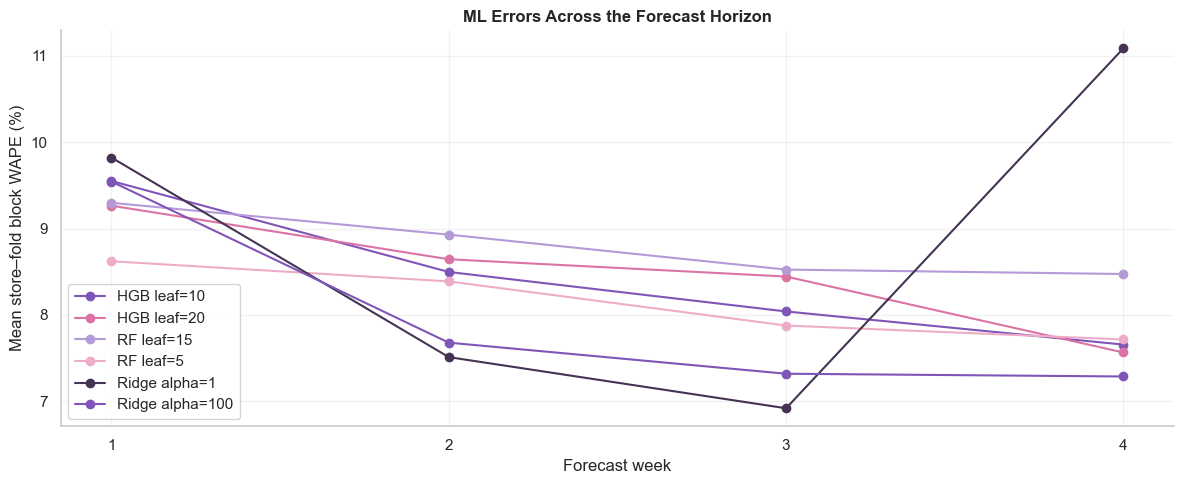

In [7]:
horizon_diagnostics = ml_predictions.copy()

horizon_diagnostics["horizon_week"] = (
    (horizon_diagnostics["horizon_step"] - 1) // 7 + 1
)
horizon_diagnostics["absolute_error"] = (
    horizon_diagnostics["prediction"]
    - horizon_diagnostics["actual"]
).abs()
horizon_diagnostics["absolute_actual"] = (
    horizon_diagnostics["actual"].abs()
)

weekly_errors = (
    horizon_diagnostics
    .groupby(["model", "fold", "store_id", "horizon_week"])
    .agg(
        absolute_error=("absolute_error", "sum"),
        absolute_actual=("absolute_actual", "sum"),
        days=("date", "size"),
    )
    .reset_index()
)

assert weekly_errors["days"].eq(7).all()

weekly_errors["WAPE_pct"] = (
    100 * weekly_errors["absolute_error"]
    / weekly_errors["absolute_actual"].where(
        weekly_errors["absolute_actual"].gt(0)
    )
)

horizon_summary = (
    weekly_errors
    .groupby(["model", "horizon_week"])["WAPE_pct"]
    .mean()
    .unstack("horizon_week")
)

display(horizon_summary)

fig, ax = plt.subplots(figsize=(12, 5))

for model_name in horizon_summary.index:
    ax.plot(
        horizon_summary.columns,
        horizon_summary.loc[model_name],
        marker="o",
        label=model_name,
    )

ax.set_xticks([1, 2, 3, 4])
ax.set_xlabel("Forecast week")
ax.set_ylabel("Mean store–fold block WAPE (%)")
ax.set_title("ML Errors Across the Forecast Horizon")
ax.legend()
plt.tight_layout()
plt.show()

weekly_errors.to_csv(
    RESULTS_DIR / "ml_cv_horizon_block_errors.csv",
    index=False,
)

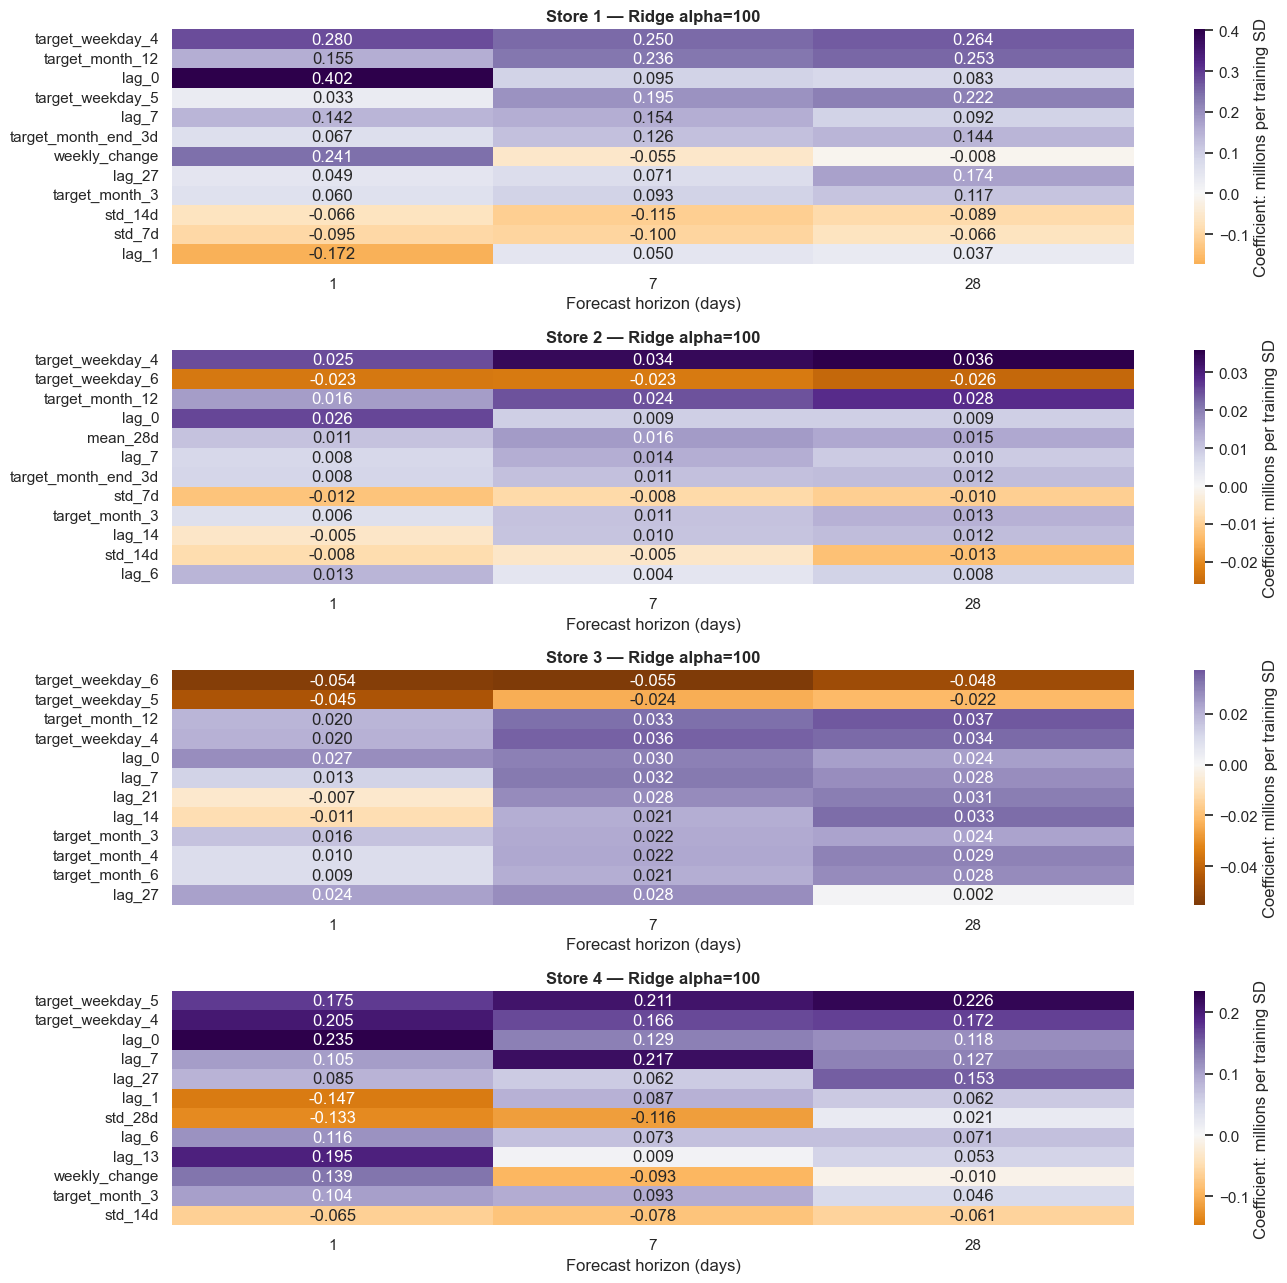

In [8]:
ridge_name = "Ridge alpha=100"
coefficient_rows = []

for store_id in sorted(store_series):
    for h in [1, 7, 28]:
        pipeline = ml_diagnostic_fits[(ridge_name, store_id, h)]
        ridge = pipeline.named_steps["ridge"]

        feature_names = ml_fold_data[
            (last_fold, store_id)
        ]["horizons"][h]["X"].columns

        for feature, coefficient in zip(feature_names, ridge.coef_):
            coefficient_rows.append({
                "store_id": store_id,
                "horizon": h,
                "feature": feature,
                "standardized_coefficient": float(coefficient),
            })

ridge_coefficients = pd.DataFrame(coefficient_rows)

# Display the strongest coefficients separately for every store.
fig, axes = plt.subplots(
    len(store_series), 1,
    figsize=(14, 13),
    squeeze=False,
)

for ax, store_id in zip(axes.flat, sorted(store_series)):
    subset = ridge_coefficients.loc[
        ridge_coefficients["store_id"].eq(store_id)
    ]

    coefficient_matrix = subset.pivot(
        index="feature",
        columns="horizon",
        values="standardized_coefficient",
    )

    top_features = (
        coefficient_matrix.abs()
        .mean(axis=1)
        .nlargest(12)
        .index
    )

    sns.heatmap(
        coefficient_matrix.loc[top_features],
        cmap="PuOr",
        center=0,
        annot=True,
        fmt=".3f",
        ax=ax,
        cbar_kws={"label": "Coefficient: millions per training SD"},
    )

    ax.set_title(f"Store {store_id} — Ridge alpha=100")
    ax.set_xlabel("Forecast horizon (days)")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

ridge_coefficients.to_csv(
    RESULTS_DIR / "ridge_last_fold_coefficients.csv",
    index=False,
)

## 4. Conclusions and Limitations

### Model comparison

Ridge with alpha=100 is the strongest tested ML configuration, with mean
store–fold WAPE of 7.931%. The leading Prophet remains slightly better
at 7.818%, while the leading classical SARIMA achieves 8.046%.

The differences are small and come from repeated model selection on
the same development folds. They do not establish statistical superiority.

### Forecast horizon

For Ridge alpha=100, mean weekly-block WAPE decreases from 9.545%
in week 1 to 7.286% in week 4. Ridge alpha=1 instead reaches 11.088%
in week 4, supporting stronger regularization in this experiment.

Horizon blocks contain different target dates, and each horizon uses
a separate model. Lower errors at longer horizons therefore do not
establish that uncertainty decreases with forecast distance.

### Features and interpretation

Features use sales available at each forecast origin and calendar
information known in advance. Validation sales are never inserted
into future lag features.

Standardized Ridge coefficients describe conditional associations.
Correlated lag and rolling features can redistribute coefficient weight,
so coefficient magnitude is not a causal importance measure.

### Limitations and next steps

Store 4 has only 94–121 complete training examples per horizon in the
first fold. This limits the complexity supported by its history.

We compare three model families with two configurations each.
The results do not represent exhaustive tuning.

We retain Ridge alpha=100 as the primary ML reference and proceed
to neural forecasting models. The final holdout remains unopened.

In [9]:
import sklearn

prediction_key = ["model", "fold", "store_id", "date"]

assert not ml_predictions.duplicated(prediction_key).any()
assert ml_predictions["date"].max() < TEST_START
assert np.isfinite(
    ml_predictions[["actual", "prediction"]].to_numpy()
).all()

counts = ml_predictions.groupby(
    ["model", "fold", "store_id"]
).size()

assert counts.eq(HORIZON).all()
assert len(counts) == len(ml_scores)

assert (
    ml_predictions
    .groupby(["fold", "store_id", "date"])["actual"]
    .nunique()
    .eq(1)
    .all()
)

ml_predictions["error"] = (
    ml_predictions["prediction"] - ml_predictions["actual"]
)
ml_predictions["absolute_error"] = ml_predictions["error"].abs()

ml_predictions.to_csv(
    RESULTS_DIR / "ml_cv_predictions.csv",
    index=False,
    date_format="%Y-%m-%d",
)

ml_scores.to_csv(
    RESULTS_DIR / "ml_cv_scores.csv", index=False
)

ml_training_audit.to_csv(
    RESULTS_DIR / "ml_training_audit.csv",
    index=False,
    date_format="%Y-%m-%d",
)

best_ml_name = (
    ml_summary.loc[ml_summary["complete_cv"]]
    .sort_values("mean_WAPE_pct")
    .index[0]
)

selection_record = {
    "status": "development comparison; final selection not frozen",
    "best_ml_candidate": best_ml_name,
    "strategy": "separate direct model per store and horizon",
    "forecast_horizon_days": HORIZON,
    "cv_folds": len(cv_schedule),
    "feature_lookback_days": 28,
    "missing_data_policy": "exclude incomplete training examples",
    "target_fitting_scale": "millions of source monetary units",
    "negative_forecasts_clipped": False,
    "holdout_used": False,
    "candidate_specs": ml_candidates,
    "versions": {
        "sklearn": sklearn.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
    },
}

with (RESULTS_DIR / "ml_selection.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(selection_record, file, ensure_ascii=False, indent=2)

print("ML results exported successfully.")
print(f"Best ML candidate: {best_ml_name}")

ML results exported successfully.
Best ML candidate: Ridge alpha=100
